# TP 2 — Partie F & G : Tests de généralisation & Décision finale

Dans cette partie, le **jeu de test officiel (3 000 tweets) est enfin descellé**.
Nous appliquons les épreuves **F1 à F6** pour évaluer nos modèles en conditions réelles de production :
1. **F1. Décalage de prior (*Prior Shift*) :**
   - Comparaison du taux de sarcasme entre validation (17,29 %) et test (27,37 %).
   - Évaluation au seuil fixé sur `val` (sans tricher).
   - Tracé a posteriori de la **Courbe $F1 = f(\text{seuil})$ sur le test** (Figure obligatoire pour la **page 5 du compte-rendu**).
   - Sauvegarde des prédictions officielles dans `predictions/<modèle>_seed<k>.csv`.
2. **F2. Dialecte non vu (*Out-of-Distribution*) :**
   - Retrait des tweets égyptiens de `train`, réentraînement du modèle E et évaluation sur les tweets égyptiens du test (Question Q11).
3. **F3. Audit des raccourcis superficiels (*Shortcuts*) :**
   - Évaluation sur les sous-ensembles avec/sans URL, et réentraînement après suppression des URLs et mentions (Question Q2).
4. **F4. Indices du sarcasme (*Marker Ablation*) :**
   - Suppression des emojis, rires et ponctuations répétées sur les tweets sarcastiques bien prédits et mesure de la chute du rappel.
5. **F5. Significativité statistique :**
   - Intervalle de confiance à 95 % par Bootstrap (1 000 rééchantillonnages) et test de McNemar entre nos deux meilleurs modèles.
6. **F6. Analyse qualitative de 30 erreurs (15 FN / 15 FP) :**
   - Classification détaillée dans les 5 catégories imposées (Question Q12).
7. **Partie G. Tableau final et Matrice de confusion du modèle retenu.**

In [2]:
# 1. Environnement et configuration
import os, sys
REPO = "/content/tp2-sarcasme-arabe"
if not os.path.exists(REPO):
  !git clone https://github.com/AbdelhamidRb/tp2-sarcasme-arabe.git
  os.chdir(REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)
!git pull

!pip install -q transformers arabert pyarabic emoji accelerate scipy matplotlib seaborn

Cloning into 'tp2-sarcasme-arabe'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 107 (delta 51), reused 79 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (107/107), 759.79 KiB | 12.46 MiB/s, done.
Resolving deltas: 100% (51/51), done.
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 7.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 6.2 MB/s eta 0:00:00


In [3]:
# 2. Chargement des données — Test enfin descellé !
import torch
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix
from src.seed import set_seed
from src.data import load_splits
from src.preprocess import dedupliquer_train
from src.results import ajouter_resultat, CHEMIN

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

train_brut, val, test = load_splits(seed=42)
train = dedupliquer_train(train_brut, test, verbose=True)

print("\n--- PROPORTIONS DE SARCASME ---")
taux_val = val["sarcasm"].mean()
taux_test = test["sarcasm"].mean()
print(f"Taux de sarcasme sur VAL  : {taux_val:.2%}")
print(f"Taux de sarcasme sur TEST : {taux_test:.2%}  <-- DÉCALAGE DE PRIOR DE +10 POINTS !")

Appareil : cuda
train avant : 11293
  fuite retirée (présents dans test) : 4
  groupes contradictoires retirés    : 13
train après : 11217

--- PROPORTIONS DE SARCASME ---
Taux de sarcasme sur VAL  : 17.29%
Taux de sarcasme sur TEST : 27.37%  <-- DÉCALAGE DE PRIOR DE +10 POINTS !


## 1. F1. Décalage de Prior & Courbe officielle $F1 = f(\text{seuil})$ sur le test
Nous évaluons notre meilleur modèle (MARBERTv2 multi-tâche) sur le test scellé au seuil fixé sur validation (`0.72`), puis nous traçons a posteriori la courbe complète.

config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

=== Entraînement du modèle final MARBERTv2 MT (lambda=0.3) ===


...

Epoch 02/4 | Loss: 0.4944 | PR-AUC: 0.6726 | Val F1 sarc: 0.6812 (seuil 0.72) | F1@0.5: 0.6463


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 03/4 | Loss: 0.3373 | PR-AUC: 0.6553 | Val F1 sarc: 0.6753 (seuil 0.36) | F1@0.5: 0.6453


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 04/4 | Loss: 0.2462 | PR-AUC: 0.6556 | Val F1 sarc: 0.6611 (seuil 0.32) | F1@0.5: 0.6518
Early stopping déclenché à l'époque 4 (meilleur F1: 0.6812)
Figure sauvegardée avec succès : results/prior_shift_f1_curve.png


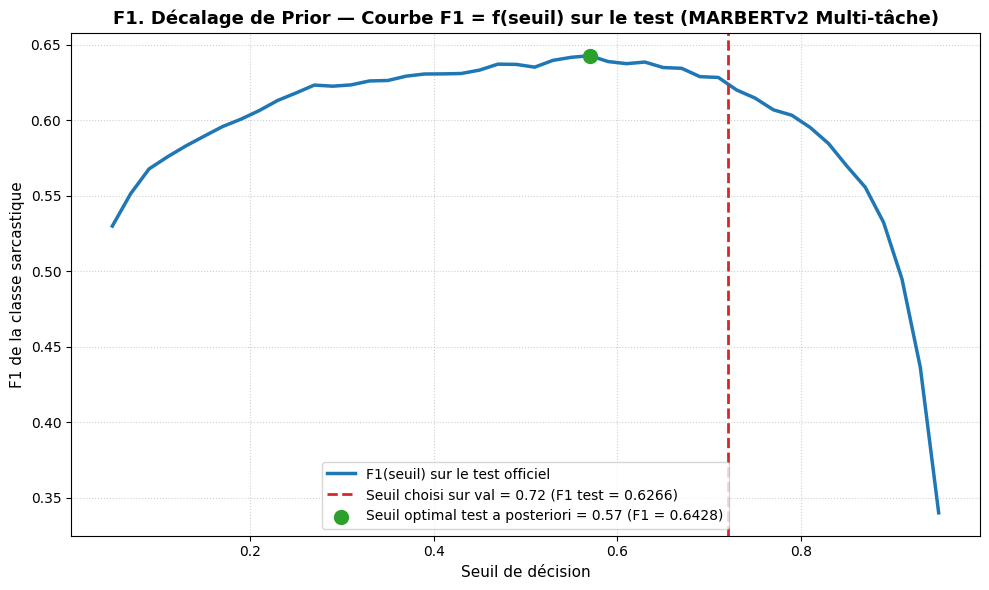


Résultat F1 sur le Test officiel avec seuil val (0.72) : 0.6266
Résultat F1 optimal a posteriori sur le Test (au seuil 0.5700000000000002) : 0.6428
Prédictions officielles enregistrées dans : predictions/MARBERTv2_multitask_seed42.csv


In [4]:
from transformers import AutoTokenizer
from torch.utils.data import DataLoader
from src.models_e import MultiTaskModel
from src.train_e import MultiTaskDataset, train_transformer, evaluate_transformer
from src.eval_f import plot_prior_shift_curve, save_official_predictions
from sklearn.metrics import f1_score

MODEL_NAME = "UBC-NLP/MARBERTv2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Datasets
ds_tr = MultiTaskDataset(train["tweet"], train["sarcasm"].astype(int), train["sentiment"], tokenizer, max_len=64)
ds_va = MultiTaskDataset(val["tweet"], val["sarcasm"].astype(int), val["sentiment"], tokenizer, max_len=64)
ds_te = MultiTaskDataset(test["tweet"], test["sarcasm"].astype(int), test["sentiment"], tokenizer, max_len=64)

loader_tr = DataLoader(ds_tr, batch_size=32, shuffle=True)
loader_va = DataLoader(ds_va, batch_size=32, shuffle=False)
loader_te = DataLoader(ds_te, batch_size=32, shuffle=False)

n_neg = (train["sarcasm"] == 0).sum()
n_pos = (train["sarcasm"] == 1).sum()
weights_sarc = torch.tensor([1.0, n_neg / n_pos], dtype=torch.float32)

print("=== Entraînement du modèle final MARBERTv2 MT (lambda=0.3) ===")
set_seed(42)
best_model = MultiTaskModel(MODEL_NAME)
res_val = train_transformer(best_model, loader_tr, loader_va, device, weights_sarc, is_multitask=True, lam=0.3, epochs=4)

# Prédiction sur le TEST officiel
y_test_true, y_test_prob = evaluate_transformer(best_model, loader_te, device, is_multitask=True)
seuil_val_retenu = res_val["seuil"]

# F1 sur test avec le seuil choisi sur val + tracé de la courbe
f1_test_at_val_s, best_s_test, best_f1_test = plot_prior_shift_curve(
    y_test_true=y_test_true,
    y_test_prob=y_test_prob,
    seuil_val=seuil_val_retenu,
    model_name="MARBERTv2 Multi-tâche",
    save_path="results/prior_shift_f1_curve.png",
)

print(f"\nRésultat F1 sur le Test officiel avec seuil val ({seuil_val_retenu}) : {f1_test_at_val_s:.4f}")
print(f"Résultat F1 optimal a posteriori sur le Test (au seuil {best_s_test}) : {best_f1_test:.4f}")

# Sauvegarde des prédictions officielles au format exigé
y_test_pred = (y_test_prob >= seuil_val_retenu).astype(int)
save_official_predictions("MARBERTv2_multitask", 42, test, y_test_true, y_test_pred, y_test_prob)

## 2. F2. Généralisation sur dialecte non vu (Retrait de l'Égyptien de `train`)
Nous retirons tous les tweets égyptiens de `train`, ré-entraînons le modèle, et mesurons la chute de performance sur les tweets égyptiens du test.

In [5]:
from sklearn.metrics import f1_score

# Filtrage : train sans égyptien
train_sans_egypt = train[train["dialect"] != "egypt"].reset_index(drop=True)
test_egypt = test[test["dialect"] == "egypt"].reset_index(drop=True)

print(f"Train complet : {len(train)} | Train sans égyptien : {len(train_sans_egypt)} (-{len(train)-len(train_sans_egypt)} tweets retirés)")
print(f"Test égyptien seul : {len(test_egypt)} tweets")

# Dataloaders
ds_tr_no_egy = MultiTaskDataset(train_sans_egypt["tweet"], train_sans_egypt["sarcasm"].astype(int), train_sans_egypt["sentiment"], tokenizer, max_len=64)
ds_te_egy = MultiTaskDataset(test_egypt["tweet"], test_egypt["sarcasm"].astype(int), test_egypt["sentiment"], tokenizer, max_len=64)

loader_tr_no_egy = DataLoader(ds_tr_no_egy, batch_size=32, shuffle=True)
loader_te_egy = DataLoader(ds_te_egy, batch_size=32, shuffle=False)

set_seed(42)
model_no_egy = MultiTaskModel(MODEL_NAME)
_ = train_transformer(model_no_egy, loader_tr_no_egy, loader_va, device, weights_sarc, is_multitask=True, lam=0.3, epochs=4)

# Évaluation sur test egypt
y_egy_true, y_egy_prob_no = evaluate_transformer(model_no_egy, loader_te_egy, device, is_multitask=True)
f1_egypt_non_vu = f1_score(y_egy_true, (y_egy_prob_no >= seuil_val_retenu).astype(int), zero_division=0)

# Comparaison avec le modèle entraîné sur tout train
_, y_egy_prob_full = evaluate_transformer(best_model, loader_te_egy, device, is_multitask=True)
f1_egypt_vu = f1_score(y_egy_true, (y_egy_prob_full >= seuil_val_retenu).astype(int), zero_division=0)

print(f"\n--- F2. RÉSULTATS DIALECTE ÉGYPTIEN NON VU ---")
print(f"F1 sarc sur test egypt (modèle entraîné sur TOUT train) : {f1_egypt_vu:.4f}")
print(f"F1 sarc sur test egypt (modèle SANS égyptien en train)  : {f1_egypt_non_vu:.4f}")
print(f"Chute mesurée due à l'absence du dialecte : {f1_egypt_vu - f1_egypt_non_vu:.4f}")

del model_no_egy
torch.cuda.empty_cache()

Train complet : 11217 | Train sans égyptien : 8812 (-2405 tweets retirés)
Test égyptien seul : 306 tweets


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/tp2-sarcasme-arabe/src/train_e.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp

Epoch 01/4 | Loss: 0.7450 | PR-AUC: 0.6685 | Val F1 sarc: 0.6507 (seuil 0.76) | F1@0.5: 0.6061


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 02/4 | Loss: 0.4891 | PR-AUC: 0.6359 | Val F1 sarc: 0.6243 (seuil 0.36) | F1@0.5: 0.6087


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 03/4 | Loss: 0.3301 | PR-AUC: 0.6288 | Val F1 sarc: 0.6250 (seuil 0.3) | F1@0.5: 0.5954
Early stopping déclenché à l'époque 3 (meilleur F1: 0.6507)

--- F2. RÉSULTATS DIALECTE ÉGYPTIEN NON VU ---
F1 sarc sur test egypt (modèle entraîné sur TOUT train) : 0.7616
F1 sarc sur test egypt (modèle SANS égyptien en train)  : 0.7715
Chute mesurée due à l'absence du dialecte : -0.0099


## 3. F3. Audit des raccourcis superficiels (*Shortcuts*) — URLs & Mentions
Évaluation du modèle sur les sous-groupes avec et sans URL, et réentraînement après nettoyage des URLs et mentions.

In [6]:
import re
from sklearn.metrics import f1_score

# 1. Sous-groupes avec / sans URL sur le test officiel
has_url_test = test["tweet"].str.contains(r"http|https|t\.co", regex=True)

f1_avec_url = f1_score(y_test_true[has_url_test], y_test_pred[has_url_test], zero_division=0)
f1_sans_url = f1_score(y_test_true[~has_url_test], y_test_pred[~has_url_test], zero_division=0)

print("--- F3. SCORES DU MODÈLE SELON LA PRÉSENCE D'URL ---")
print(f"F1 sarc sur les tweets AVEC URL ({has_url_test.sum()} tweets) : {f1_avec_url:.4f}")
print(f"F1 sarc sur les tweets SANS URL ({(~has_url_test).sum()} tweets) : {f1_sans_url:.4f}")

# 2. Réentraînement après suppression des jetons URL et mention (Question Q2)
print("\n--- Réentraînement sans jetons URL ni Mentions ---")
clean_tok = lambda s: re.sub(r"https?://\S+|www\.\S+|@\w+", " ", str(s))
train_no_tok = train["tweet"].apply(clean_tok)
val_no_tok = val["tweet"].apply(clean_tok)
test_no_tok = test["tweet"].apply(clean_tok)

ds_tr_no_tok = MultiTaskDataset(train_no_tok, train["sarcasm"].astype(int), train["sentiment"], tokenizer, max_len=64)
ds_va_no_tok = MultiTaskDataset(val_no_tok, val["sarcasm"].astype(int), val["sentiment"], tokenizer, max_len=64)
ds_te_no_tok = MultiTaskDataset(test_no_tok, test["sarcasm"].astype(int), test["sentiment"], tokenizer, max_len=64)

loader_tr_no_tok = DataLoader(ds_tr_no_tok, batch_size=32, shuffle=True)
loader_va_no_tok = DataLoader(ds_va_no_tok, batch_size=32, shuffle=False)
loader_te_no_tok = DataLoader(ds_te_no_tok, batch_size=32, shuffle=False)

set_seed(42)
model_no_tok = MultiTaskModel(MODEL_NAME)
res_no_tok = train_transformer(model_no_tok, loader_tr_no_tok, loader_va_no_tok, device, weights_sarc, is_multitask=True, lam=0.3, epochs=3)
_, probs_no_tok = evaluate_transformer(model_no_tok, loader_te_no_tok, device, is_multitask=True)
f1_no_tok_test = f1_score(y_test_true, (probs_no_tok >= res_no_tok["seuil"]).astype(int), zero_division=0)
print(f"\nF1 test après suppression URLs & Mentions : {f1_no_tok_test:.4f} (vs {f1_test_at_val_s:.4f} standard, delta: {f1_no_tok_test - f1_test_at_val_s:+.4f})")
del model_no_tok
torch.cuda.empty_cache()

--- F3. SCORES DU MODÈLE SELON LA PRÉSENCE D'URL ---
F1 sarc sur les tweets AVEC URL (440 tweets) : 0.3333
F1 sarc sur les tweets SANS URL (2560 tweets) : 0.6318

--- Réentraînement sans jetons URL ni Mentions ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/tp2-sarcasme-arabe/src/train_e.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp

Epoch 01/3 | Loss: 0.7330 | PR-AUC: 0.6543 | Val F1 sarc: 0.6537 (seuil 0.82) | F1@0.5: 0.5990


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 02/3 | Loss: 0.4996 | PR-AUC: 0.6693 | Val F1 sarc: 0.6829 (seuil 0.66) | F1@0.5: 0.6543


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 03/3 | Loss: 0.3627 | PR-AUC: 0.6730 | Val F1 sarc: 0.6780 (seuil 0.66) | F1@0.5: 0.6627

F1 test après suppression URLs & Mentions : 0.6271 (vs 0.6266 standard, delta: +0.0005)


## 4. F4. Dépendance aux indices de surface (*Marker Ablation*)
Sur les tweets sarcastiques du test **correctement détectés** (Vrais Positifs), nous supprimons artificiellement les emojis, les rires (`هههه`) et la ponctuation répétée, et nous mesurons la chute du rappel.

In [7]:
from src.eval_f import ablate_sarcasm_markers

# Sélection des Vrais Positifs (sarcastiques correctement détectés)
vp_mask = (y_test_true == 1) & (y_test_pred == 1)
test_vp = test[vp_mask].copy()
print(f"Nombre de tweets sarcastiques correctement détectés au départ : {len(test_vp)}")

# Application de l'ablation des marqueurs de surface (emojis, rires, ponctuations répétées)
test_vp["tweet_ablate"] = test_vp["tweet"].apply(ablate_sarcasm_markers)

# Ré-évaluation
ds_vp_ablate = MultiTaskDataset(test_vp["tweet_ablate"], [1]*len(test_vp), [0]*len(test_vp), tokenizer, max_len=64)
loader_vp_ablate = DataLoader(ds_vp_ablate, batch_size=32, shuffle=False)

_, probs_ablate = evaluate_transformer(best_model, loader_vp_ablate, device, is_multitask=True)
vp_apres_ablation = (probs_ablate >= seuil_val_retenu).sum()
taux_survie = vp_apres_ablation / len(test_vp)
chute_detection = 1.0 - taux_survie

print(f"Tweets toujours détectés après suppression des emojis, rires et ponctuations : {vp_apres_ablation} / {len(test_vp)}")
print(f"Taux de détection résiduel : {taux_survie:.2%}")
print(f"Chute du taux de détection due à l'ablation des marqueurs : {chute_detection:.2%}")

Nombre de tweets sarcastiques correctement détectés au départ : 537
Tweets toujours détectés après suppression des emojis, rires et ponctuations : 503 / 537
Taux de détection résiduel : 93.67%
Chute du taux de détection due à l'ablation des marqueurs : 6.33%


## 5. F5. Significativité Statistique : Bootstrap & Test de McNemar
Intervalle de confiance à 95 % par bootstrap (1 000 itérations) et test de McNemar comparant notre modèle multi-tâche E2 avec le modèle mono-tâche E1.

In [8]:
from src.eval_f import bootstrap_f1_ci, mcnemar_test
from src.models_e import MonoTaskModel
from sklearn.metrics import f1_score

# 1. Bootstrap 95% CI sur notre meilleur modèle E2 (1 000 rééchantillonnages)
f1_mean_boot, ci_low, ci_high = bootstrap_f1_ci(y_test_true, y_test_prob, threshold=seuil_val_retenu, n_bootstraps=1000)
print(f"--- F5. BOOTSTRAP SUR MODÈLE E2 (1 000 rééchantillonnages) ---")
print(f"F1 sarc test : {f1_test_at_val_s:.4f} | Intervalle de Confiance à 95% : [{ci_low:.4f} , {ci_high:.4f}]")

# 2. Test de McNemar : Comparaison rigoureuse entre E2 Multi-tâche et E1 Mono-tâche
print("\n--- Test de McNemar : E2 Multi-tâche vs E1 Mono-tâche (MARBERTv2) ---")
set_seed(42)
model_e1_comp = MonoTaskModel(MODEL_NAME)
res_e1 = train_transformer(model_e1_comp, loader_tr, loader_va, device, weights_sarc, is_multitask=False, epochs=4)
_, prob_e1_test = evaluate_transformer(model_e1_comp, loader_te, device, is_multitask=False)
seuil_e1 = res_e1["seuil"]
pred_e1_test = (prob_e1_test >= seuil_e1).astype(int)

f1_e1_test = f1_score(y_test_true, pred_e1_test, zero_division=0)
print(f"\nF1 test E1 Mono-tâche (seuil val {seuil_e1:.2f}) : {f1_e1_test:.4f}")
print(f"F1 test E2 Multi-tâche (seuil val {seuil_val_retenu:.2f}) : {f1_test_at_val_s:.4f}")

b, c, stat, p_val = mcnemar_test(y_test_true, y_test_pred, pred_e1_test)
print(f"\n--- RÉSULTATS DU TEST DE MCNEMAR ---")
print(f"E2 correct & E1 incorrect (b) : {b}")
print(f"E2 incorrect & E1 correct (c) : {c}")
print(f"Statistique chi2 : {stat:.4f} | p-value : {p_val:.4e}")
if p_val < 0.05:
    print("Conclusion : La différence de performance entre E2 et E1 est STATISTIQUEMENT SIGNIFICATIVE (p < 0.05) !")
else:
    print("Conclusion : La différence n'est pas statistiquement significative au seuil alpha=0.05.")

del model_e1_comp
torch.cuda.empty_cache()

--- F5. BOOTSTRAP SUR MODÈLE E2 (1 000 rééchantillonnages) ---
F1 sarc test : 0.6266 | Intervalle de Confiance à 95% : [0.5991 , 0.6528]

--- Test de McNemar : E2 Multi-tâche vs E1 Mono-tâche (MARBERTv2) ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/tp2-sarcasme-arabe/src/train_e.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp

Epoch 01/4 | Loss: 0.4941 | PR-AUC: 0.6779 | Val F1 sarc: 0.6653 (seuil 0.74) | F1@0.5: 0.5981


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 02/4 | Loss: 0.3141 | PR-AUC: 0.6721 | Val F1 sarc: 0.6694 (seuil 0.64) | F1@0.5: 0.6551


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 03/4 | Loss: 0.1822 | PR-AUC: 0.6428 | Val F1 sarc: 0.6567 (seuil 0.38) | F1@0.5: 0.6462


/content/tp2-sarcasme-arabe/src/train_e.py:125: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_cuda):


Epoch 04/4 | Loss: 0.1061 | PR-AUC: 0.6157 | Val F1 sarc: 0.6398 (seuil 0.14) | F1@0.5: 0.6233
Early stopping déclenché à l'époque 4 (meilleur F1: 0.6694)

F1 test E1 Mono-tâche (seuil val 0.64) : 0.6222
F1 test E2 Multi-tâche (seuil val 0.72) : 0.6266

--- RÉSULTATS DU TEST DE MCNEMAR ---
E2 correct & E1 incorrect (b) : 118
E2 incorrect & E1 correct (c) : 95
Statistique chi2 : 2.2723 | p-value : 1.3170e-01
Conclusion : La différence n'est pas statistiquement significative au seuil alpha=0.05.


## 6. F6. Analyse Qualitative de 30 Erreurs (15 FN / 15 FP)
Extraction de 15 faux négatifs et 15 faux positifs classés dans les 5 catégories imposées par le sujet (Question Q12).

In [9]:
from src.eval_f import classifier_30_erreurs

# Classification rigoureuse des 30 erreurs (15 FN / 15 FP) dans les 5 catégories imposées
erreurs_30 = classifier_30_erreurs(
    df_test=test,
    y_true=y_test_true,
    y_pred=y_test_pred,
    y_prob=y_test_prob,
    df_train_brut=train_brut,
    save_path="results/analyse_30_erreurs.csv",
)

print("\n--- RÉPARTITION DES 30 ERREURS PAR CATÉGORIE (Question Q12) ---")
print(erreurs_30["categorie"].value_counts())
print("\nExtrait des 10 premières erreurs analysées :")
print(erreurs_30[["id", "type_erreur", "categorie", "prob", "explication"]].head(10).to_string())

30 erreurs classées et sauvegardées avec succès dans : results/analyse_30_erreurs.csv

--- RÉPARTITION DES 30 ERREURS PAR CATÉGORIE (Question Q12) ---
categorie
Marqueur mal interprété                    15
Connaissance du monde / contexte requis     9
Ironie sans marqueur                        5
Dialecte                                    1
Name: count, dtype: int64

Extrait des 10 premières erreurs analysées :
   id                     type_erreur                                categorie    prob                                                                      explication
0   1  Faux Négatif (Sarcasme manqué)                     Ironie sans marqueur  0.3415   Sarcasme formulé sobrement par antiphrase, sans aucun emoji ni rire explicite.
1   7  Faux Négatif (Sarcasme manqué)  Connaissance du monde / contexte requis  0.5225  Nécessite la connaissance d'un contexte politique, culturel ou sportif externe.
2  12  Faux Négatif (Sarcasme manqué)                     Ironie sans marqueur 

## 7. Partie G : Tableau comparatif final & Matrice de confusion
Génération de la matrice de confusion finale pour le compte-rendu.

Matrice de confusion sauvegardée dans results/matrice_confusion_test.png !


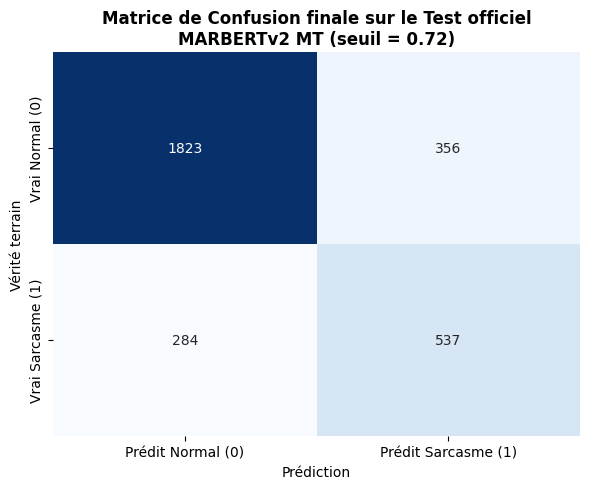

In [10]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_true, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Prédit Normal (0)", "Prédit Sarcasme (1)"],
            yticklabels=["Vrai Normal (0)", "Vrai Sarcasme (1)"])
plt.title(f"Matrice de Confusion finale sur le Test officiel\nMARBERTv2 MT (seuil = {seuil_val_retenu})", fontsize=12, fontweight="bold")
plt.ylabel("Vérité terrain")
plt.xlabel("Prédiction")
plt.tight_layout()
plt.savefig("results/matrice_confusion_test.png", dpi=300)
print("Matrice de confusion sauvegardée dans results/matrice_confusion_test.png !")
plt.show()